# LASSI - Power Efficiency

***OLLAMA API*** + ***Argo Gateway API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

## Setup

In [1]:
import os

# Import LASSI modules
import lassi.llm_config
import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline
%aimport lassi.get_power
%aimport lassi.argostream_curl

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [2]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.

    -- matrix-rotate ["10000", "1"]
    -- jacobi [""] (none required)
    -- DNU -- mallocFree ["10000"]
    -- layout ["1"]
    -- atomicCost ["1"]
    -- dense-embedding ["10000", "8", "1"]
    -- pathfinder ["10000", "1000", "1000"]
    -- bsearch ["10000", "1"]
    -- entropy ["10000", "1024", "1"]
    -- colorwheel ["10000", "8", "1"]
    -- randomAccess ["1"]
    -- lid-driven-cavity [""]
    """
    
    app_folder_name = "lid-driven-cavity"

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context = True  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    if source_lang == "CUDA":
        code_compiler = "nvcc"
        code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_60 -O3"
        # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
        # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = [""]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    model = "gpto1preview"  # (max token = 128000)
    model_coder = "gpt4o"  # (max token = 128000)
    # model = "gpto1preview"  # (max token = 128000)

    # -- FROM OLLAMA
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "qwq:latest"  # (max token = 32768)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 128000
    num_ctx_coder = 128000

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpto1preview"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "03test_o1p_ee_context_fewsht_compare"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder, llm_source, use_context,
            context_knowledge_selection, code_compiler, code_compiler_kwds, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Application: lid-driven-cavity

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpto1preview
Model coder: gpt4o
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpto1preview/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp03test_o1p_ee_context_fewsht_compare

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

LLM Prompt for Code Generation: 

Carefully follow all these instructions step-by-step: 
STEP 1. Read the background knowledge and your background knowledge summaries about programming and energy-efficiency strategies. 
STEP 2. Read your description and 

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Execute command: ['./lid-driven-cavity-cuda_main', '']

Problem size: 512 x 512 
Time = 0.000477, delt = 4.768372e-04, iter = 92522, res = 9.999751e-04
Time = 0.000954, delt = 4.768372e-04, iter = 88410, res = 9.999561e-04
Time = 0.001000, delt = 4.632568e-05, iter = 86674, res = 9.999808e-04

Total execution time of the iteration loop: 21.291248 (s)
GPU power data has been written to source_CUDA_gpu_power_results.csv


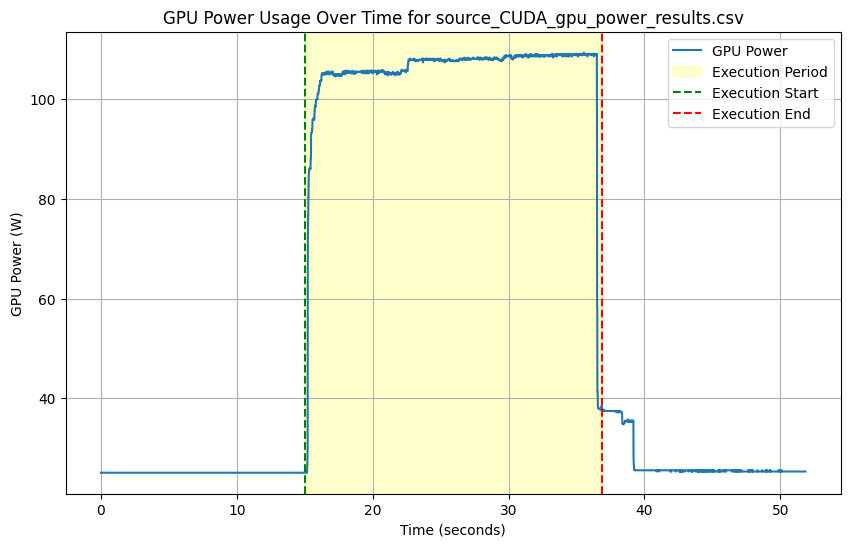

Start time: 15.001 -- End time: 36.852

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 21.85 seconds
Total GPU energy consumption for source_CUDA_gpu_power_results.csv:
  0.000639 kWh
  0.6393 Wh
  2301.65 J
Average GPU power: 105.38 W
Total Energy During Exe Runtime:   2301.65 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


Measure system idle power...
Duration for idle time measurement: 21.85
GPU power data has been written to idle__gpu_power_results.csv


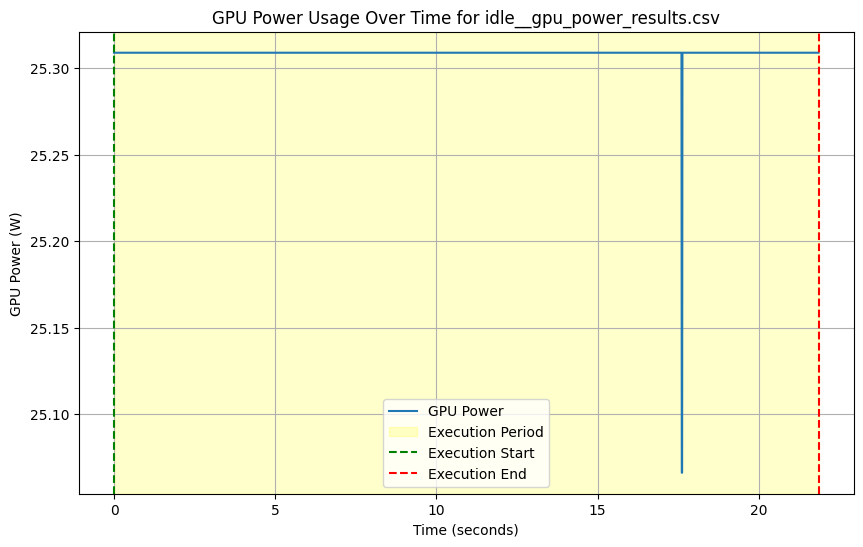

Start time: 0 -- End time: 21.851

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 21.85 seconds
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000154 kWh
  0.1537 Wh
  553.30 J
Average GPU power: 25.31 W
Total Energy During Exe Runtime:   553.30 J
----------------------------------------------------------------------------------------------------------------------------------------





----- STARTING LLM CONTEXT BUILDING WITH SELF-PROMPTING -----


GPU Memory Status:
 GPU 0: 114 MiB used, 16269 MiB free, 16384 MiB total
 GPU 1: 114 MiB used, 16269 MiB free, 16384 MiB total

--> ... prompt LLM to summarize context knowledge.
**Key Relevant Points for Refactoring CUDA C++ Code to Improve Energy Efficiency:**

1. **Minimize Data Transfer Between Host and Device (High Priority):**

   - **Reduce Host-Device Transfers:** Limit the frequency and volume of data transfers between the CPU (host) and GPU (device), as these operation

**Key Relevant Points for Refactoring CUDA C++ Code to Improve Energy Efficiency:**

1. **Minimize Data Transfer Between Host and Device (High Priority):**

   - **Reduce Host-Device Transfers:** Limit the frequency and volume of data transfers between the CPU (host) and GPU (device), as these operations are costly in terms of energy and performance.
   - **Device-Resident Data Structures:** Create and work with intermediate data structures entirely within device memory to avoid unnecessary data movement.
   - **Batch Transfers:** When data transfer is necessary, batch multiple small transfers into a single larger transfer to reduce overhead and improve bandwidth utilization.
   - **Use Pinned Memory:** Utilize page-locked (pinned) host memory to achieve higher data transfer bandwidth between the host and device.

2. **Optimize Memory Usage:**

   - **Prefer Shared Memory Over Global Memory (High Priority):** Use shared memory for data that is accessed frequently by multiple threads within the same block, reducing the need for slower global memory accesses.
   - **Efficient Memory Access Patterns:** Align data structures and access patterns to enable coalesced memory accesses, which combine memory operations and reduce latency.
   - **Avoid Global Memory When Possible:** Minimize the use of global memory, as it has higher latency compared to shared memory and can significantly impact energy consumption and performance.

3. **Maintain High Occupancy (Medium Priority):**

   - **Sufficient Active Threads:** Ensure that there are enough active threads per multiprocessor to hide memory latency and keep the GPU cores busy.
   - **Optimize Thread Count:** Adjust the number of threads and blocks to achieve high occupancy without exceeding the hardware limits of the GPU.

4. **Configure Threads and Blocks Appropriately:**

   - **Threads Per Block Multiple of Warp Size (Medium Priority):** Use a number of threads per block that is a multiple of 32 (the warp size) to maximize execution efficiency and enable memory coalescing.
   - **Balance Resources:** Optimize the block size to balance resource usage (registers, shared memory) and occupancy.

5. **Avoid Warp Divergence (High Priority):**

   - **Uniform Execution Paths:** Minimize divergent branches within warps by ensuring that threads within the same warp follow the same execution path.
   - **Structure Conditional Statements:** Write conditional statements and loops in a way that aligns thread execution paths, reducing serialization and improving energy efficiency.
   - **Use Explicit Synchronization:** Utilize `__syncwarp()` to manually synchronize divergent warps if necessary, ensuring efficient reconvergence.

6. **Utilize Fast Math Functions (Medium Priority):**

   - **Use Intrinsic Functions:** Replace standard math functions with faster, lower-precision intrinsic functions (e.g., `__sinf()`, `__expf()`) when full precision is not required.
   - **Selective Optimization:** Introduce fast math functions selectively in performance-critical sections where the reduced accuracy is acceptable.
   - **Avoid Automatic Type Conversions:** Use single-precision constants (e.g., `1.0f` instead of `1.0`) to prevent unnecessary type conversions that can introduce extra instructions.

7. **Prefer Specialized Math Functions:**

   - **Use Efficient Exponentials:** Replace general exponentiation functions like `pow()` with specialized functions like `exp2()`, `exp10()`, or explicit multiplication for small integer powers.
   - **Leverage Trigonometric Identities:** Use functions like `sinpi()`, `cospi()`, and `sincospi()` when dealing with angles in terms of π to improve both accuracy and performance.
   - **Avoid Expensive Functions:** Recognize that functions like `pow()` are computationally intensive due to their generality and should be avoided if a simpler function suffices.

8. **Optimize Arithmetic Operations:**

   - **Use Shift Operations Over Division and Modulo (Low Priority):** Replace expensive division and modulo operations with bitwise shift and mask operations when dealing with powers of two.
   - **Example Optimization:** For `n` being a power of two, replace `i / n` with `i >> log2(n)` and `i % n` with `i & (n - 1)`.

9. **Improve Compiler Optimization Opportunities:**

   - **Use Signed Integers for Loop Counters (Low Medium Priority):** Declare loop counters as signed integers to enable the compiler to perform more aggressive optimizations.
   - **Facilitate Loop Unrolling:** Write loops and conditional statements that are conducive to compiler optimizations like loop unrolling and branch predication.
   - **Use Pragma Directives:** Utilize `#pragma unroll` to guide the compiler in unrolling loops where beneficial.

10. **Leverage Asynchronous Execution and Synchronization:**

    - **Use Asynchronous Operations:** Apply asynchronous memory copies (`cuda::memcpy_async`) and computations to overlap data transfer and computation, thereby improving energy efficiency.
    - **Synchronize Efficiently:** Use appropriate synchronization mechanisms (`__syncthreads()`, CUDA barriers) to coordinate threads without incurring unnecessary waiting times.
    - **Understand Thread Scopes:** Be aware of different thread scopes for synchronization (e.g., thread, block, device, system) and use them appropriately to optimize performance.

11. **Understand and Utilize Memory Hierarchy:**

    - **Optimize Use of Memory Spaces:** Exploit different memory spaces (registers, shared memory, local memory, global memory) based on their latency and bandwidth characteristics.
    - **Use Constant and Texture Memory:** For read-only data, utilize constant and texture memory spaces which are cached and can offer performance benefits.
    - **Manage Memory Lifetime:** Allocate and free device memory judiciously to prevent memory leaks and reduce unnecessary memory operations.

12. **Efficient Thread Collaboration:**

    - **Share Data Within Blocks:** Use shared memory to facilitate data sharing between threads within the same block efficiently.
    - **Minimize Synchronization Overhead:** Organize threads and memory access patterns to reduce the need for frequent synchronization, which can stall threads and waste energy.

13. **Utilize Thread Block Clusters (Advanced):**

    - **Co-schedule Thread Blocks:** For GPUs supporting compute capability 9.0 or higher, consider using thread block clusters to co-schedule blocks that can share data and synchronize at a higher level.
    - **Use Distributed Shared Memory:** Leverage distributed shared memory available to clusters to reduce global memory accesses further.
    - **Understand Hardware Capabilities:** Be mindful of the GPU's compute capability and utilize features like thread block clusters where appropriate for additional energy savings.

14. **Adopt Heterogeneous Programming Strategies:**

    - **Balance Host and Device Workloads:** Offload computations to the GPU only when it leads to overall efficiency gains; avoid unnecessary kernel launches that do not provide performance benefits over CPU execution.
    - **Use Unified Memory Appropriately:** While Unified Memory can simplify programming, be cautious of its performance implications and manage data placement explicitly when performance and energy efficiency are critical.

By focusing on these key areas, you can refactor your CUDA C++ code to enhance energy efficiency without compromising the original functionality. Implementing these best practices reduces unnecessary computations and memory operations, leverages the GPU hardware more effectively, and results in code that runs faster while consuming less power.

GPU Memory Status:
 GPU 0: 114 MiB used, 16269 MiB free, 16384 MiB total
 GPU 1: 114 MiB used, 16269 MiB free, 16384 MiB total

--> ... prompt LLM to describe the source code.
**Description and Analysis of the CUDA C++ Code for 2D Lid-Driven Cavity Problem**

---

**Overview:**

The provided CUDA C++ code is a GPU-accelerated solver for the 2D lid-driven cavity problem, which involves solving the incompressible, isothermal Navier–Stokes equations using the finite difference method. The simulation models fluid flow within a square cavity where the lid (top boundary) moves with a constant velocity, inducing circulation within the cavity. The code leverages CUDA to perform parallel computations on the GPU, aiming to achieve high performance for large grid resolutions.

---

**Major Data Structures:**

1. **Grids and Arrays:**
   - **`u` and `v`:** Arrays representing the velocity components in the x (horizontal) and y (vertical) directions, respectively. These are stored on a staggered gr

**Description and Analysis of the CUDA C++ Code for 2D Lid-Driven Cavity Problem**

---

**Overview:**

The provided CUDA C++ code is a GPU-accelerated solver for the 2D lid-driven cavity problem, which involves solving the incompressible, isothermal Navier–Stokes equations using the finite difference method. The simulation models fluid flow within a square cavity where the lid (top boundary) moves with a constant velocity, inducing circulation within the cavity. The code leverages CUDA to perform parallel computations on the GPU, aiming to achieve high performance for large grid resolutions.

---

**Major Data Structures:**

1. **Grids and Arrays:**
   - **`u` and `v`:** Arrays representing the velocity components in the x (horizontal) and y (vertical) directions, respectively. These are stored on a staggered grid to enhance numerical stability.
   - **`F` and `G`:** Intermediate arrays used in the discretization of the momentum equations. They store provisional velocity values before the pressure correction step.
   - **`pres_red` and `pres_black`:** Arrays holding pressure values for the red and black cells in a red-black checkerboard pattern used in the Gauss-Seidel iteration with Successive Over-Relaxation (SOR).
   - **`res`:** Array used to store residuals of the pressure Poisson equation to monitor convergence.
   - **`max_u_arr` and `max_v_arr`:** Arrays to store maximum velocity values in the x and y directions from different thread blocks for determining the time step size.
   - **Constants:**
     - **`NUM`:** Grid resolution along one axis (number of cells).
     - **`BLOCK_SIZE`:** Number of threads per CUDA thread block.
     - **`dx` and `dy`:** Mesh sizes in the x and y directions, respectively.
     - **Physical and Numerical Parameters:**
       - **`Re_num`:** Reynolds number controlling the viscous effects in the simulation.
       - **`omega`:** Relaxation factor for the SOR iterative solver.
       - **`mix_param`:** Discretization mixture parameter (gamma) controlling the upwind differencing.

2. **Macros for Indexing:**
   - Macros such as `u(I, J)`, `v(I, J)`, etc., are defined to map two-dimensional indices to one-dimensional array access, simplifying code readability and maintenance.

---

**Major Functions:**

1. **Boundary Condition Functions:**
   - **`set_BCs_host(Real* u, Real* v)`:**
     - **Purpose:** Sets the initial boundary conditions for velocity components `u` and `v` on the host (CPU) before transferring data to the device (GPU).
     - **Details:** Implements the physical boundary conditions specific to the lid-driven cavity problem, such as zero velocities on the stationary walls and a specified velocity (`ustar`) on the moving lid.

   - **`__global__ void set_BCs(Real* u, Real* v)`:**
     - **Purpose:** CUDA kernel that updates the boundary conditions for `u` and `v` on the device during the simulation.
     - **Details:** Ensures that boundary conditions are maintained at each time step on the GPU.

2. **Intermediate Calculations for Momentum Equations:**
   - **`__global__ void calculate_F(const Real dt, const Real* u, const Real* v, Real* F)`:**
     - **Purpose:** Computes the provisional velocity field `F` in the x-direction using the discretized momentum equations.
     - **Details:** Applies finite difference approximations for convection and diffusion terms, incorporating the body force `gx`.

   - **`__global__ void calculate_G(const Real dt, const Real* u, const Real* v, Real* G)`:**
     - **Purpose:** Computes the provisional velocity field `G` in the y-direction.
     - **Details:** Similar to `calculate_F`, but for the vertical momentum equation, incorporating the body force `gy`.

3. **Pressure Solver Functions:**
   - **Boundary Conditions for Pressure:**
     - **`__global__ void set_horz_pres_BCs(Real* pres_red, Real* pres_black)`:**
       - **Purpose:** Sets the horizontal boundary conditions for the pressure field.
     - **`__global__ void set_vert_pres_BCs(Real* pres_red, Real* pres_black)`:**
       - **Purpose:** Sets the vertical boundary conditions for the pressure field.

   - **Red-Black Gauss-Seidel Iteration Kernels:**
     - **`__global__ void red_kernel(const Real dt, const Real* F, const Real* G, const Real* pres_black, Real* pres_red)`:**
       - **Purpose:** Updates the pressure values at red cells using the SOR method.
       - **Details:** Computes the new pressure based on neighboring black cell values and the divergence of provisional velocities.
     - **`__global__ void black_kernel(const Real dt, const Real* F, const Real* G, const Real* pres_red, Real* pres_black)`:**
       - **Purpose:** Updates the pressure values at black cells.
       - **Details:** Similar to `red_kernel`, but operates on black cells using neighboring red cell values.

   - **Residual Calculation:**
     - **`__global__ void calc_residual(const Real dt, const Real* F, const Real* G, const Real* pres_red, const Real* pres_black, Real* res_array)`:**
       - **Purpose:** Calculates the residuals of the pressure Poisson equation to assess convergence.
       - **Details:** Computes the difference between the left-hand side and right-hand side of the discretized pressure equation, storing squared residuals for each cell.

   - **Pressure Norm Calculation:**
     - **`__global__ void sum_pressure(const Real* pres_red, const Real* pres_black, Real* pres_sum)`:**
       - **Purpose:** Computes the L2 norm of the pressure field to normalize the residuals.
       - **Details:** Sums the squares of the pressure values over the entire grid.

4. **Velocity Update Functions:**
   - **`__global__ void calculate_u(const Real dt, const Real* F, const Real* pres_red, const Real* pres_black, Real* u, Real* max_u)`:**
     - **Purpose:** Updates the velocity component `u` based on the corrected pressures and calculates the maximum `u` for time step control.
     - **Details:** Adjusts the provisional velocity `F` by the pressure gradient and finds the maximum absolute `u` value within each thread block.

   - **`__global__ void calculate_v(const Real dt, const Real* G, const Real* pres_red, const Real* pres_black, Real* v, Real* max_v)`:**
     - **Purpose:** Similar to `calculate_u`, but for the velocity component `v`.

---

**Main Function (`int main(int argc, char *argv[])`):**

- **Initialization:**
  - Allocates memory for all arrays on the host.
  - Initializes velocity and pressure fields to zero.
  - Sets initial boundary conditions using `set_BCs_host`.
  - Allocates device memory and transfers initial data to the GPU.

- **Simulation Parameters:**
  - Defines simulation time range (`time_start`, `time_end`) and initial time step size (`dt`).
  - Calculates stable time step size based on the grid resolution and Reynolds number.

- **Time Integration Loop:**
  - **Time Step Calculation:**
    - Determines the time step `dt` based on the Courant–Friedrichs–Lewy (CFL) condition and viscous stability criteria.
    - Ensures that the simulation does not overshoot the `time_end`.

  - **Compute Provisional Velocities:**
    - Calls `calculate_F` and `calculate_G` to compute provisional velocities `F` and `G`.

  - **Pressure Correction Loop (SOR Iteration):**
    - **Initialization:**
      - Calculates the initial L2 norm of the pressure field for normalization.
    - **Iteration:**
      - Alternates between updating red and black pressure cells using `red_kernel` and `black_kernel`.
      - Updates pressure boundary conditions.
      - Calculates the residual using `calc_residual`.
      - Checks for convergence by comparing the normalized residual to the specified tolerance (`tol`).

  - **Velocity Correction:**
    - Updates the velocity fields `u` and `v` using `calculate_u` and `calculate_v`.
    - Retrieves maximum velocities from the GPU to adjust the time step size.

  - **Boundary Condition Update:**
    - Calls `set_BCs` to update boundary conditions on the GPU.

  - **Time Increment:**
    - Increments the simulation time by `dt`.

- **Finalization:**
  - Transfers the final velocity and pressure fields from the GPU to the host.
  - Writes the velocity data to a file (`velocity_gpu.dat`) for post-processing and visualization.
  - Frees allocated memory on both the host and device.

---

**Analysis:**

- **Algorithmic Approach:**
  - The code implements a classic computational fluid dynamics (CFD) approach for solving the Navier–Stokes equations using finite difference methods on a uniform grid.
  - The staggered grid arrangement is used to avoid pressure-velocity decoupling, enhancing numerical stability.
  - The red-black Gauss-Seidel method with SOR accelerates the convergence of the iterative pressure Poisson equation solver.

- **Parallelization Strategy:**
  - The computationally intensive tasks are parallelized using CUDA kernels, allowing simultaneous computations across the grid.
  - Shared memory is utilized within kernels (e.g., in `sum_pressure`, `calc_residual`, `calculate_u`, and `calculate_v`) to perform reductions and store intermediate sums or maxima efficiently.
  - Thread blocks and grid dimensions are carefully chosen based on the problem size (`NUM`) and the defined `BLOCK_SIZE` to maximize occupancy and performance.

- **Dynamic Time Stepping:**
  - The time step size `dt` is dynamically adjusted during the simulation to satisfy stability conditions, which is crucial for explicit time integration methods.
  - The maximum velocities are used to enforce the CFL condition, ensuring accurate and stable simulation results.

- **Boundary Conditions Handling:**
  - Boundary conditions are consistently enforced both at the beginning of the simulation and at each time step, crucial for accurately modeling the physical problem.
  - Separate functions for setting boundary conditions on the host and device improve code organization.

- **Performance Considerations:**
  - The code includes optimizations such as avoiding redundant calculations, minimizing global memory access by reusing loaded values, and employing shared memory for reductions.
  - The use of predefined macros for indexing enhances code readability and may assist the compiler in optimization.
  - Care is taken to minimize data transfers between the host and device, with most computation and data residing on the GPU after initial setup.

- **Numerical Stability and Convergence:**
  - The SOR relaxation parameter (`omega`) is set to 1.7, a value commonly used to accelerate convergence without sacrificing stability.
  - The residual calculation and normalization using the initial pressure norm (`p0_norm`) are essential for monitoring and ensuring the convergence of the pressure solver.

- **Output and Post-Processing:**
  - The final velocity fields are written to a file in a tabulated format, facilitating easy post-processing and visualization using tools like MATLAB or Python.

---

**Conclusion:**

The provided CUDA C++ code efficiently solves the 2D lid-driven cavity flow problem by leveraging GPU acceleration and parallel computation techniques. The code is well-structured, with clear separation of functionalities into distinct kernels and functions. It demonstrates good CUDA programming practices by minimizing data transfer between the host and device, optimizing memory access patterns, and ensuring sufficient occupancy. The use of dynamic time stepping and careful handling of boundary conditions contributes to both the accuracy and efficiency of the simulation.

GPU Memory Status:
 GPU 0: 114 MiB used, 16269 MiB free, 16384 MiB total
 GPU 1: 114 MiB used, 16269 MiB free, 16384 MiB total


----- REVIEW THE INSTRUCTIONS TASK PROMPT  (prompt with code, token count: 20684): 



[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] Chapter 5. Programming Model This chapter introduces the main concepts behind the CUDA programming model by outlining how they are exposed in C++. An extensive description of CUDA C++ is given in Programming Interface. Full code for the vector addition example used in this chapter and the next can be found in the vectorAdd CUDA sample. 5. 1. Kernels CUDA C++ extends C++ by allowing the programmer to define C++ functions, called kernels, that, when called, are executed N times in parallel by N different CUDA threads, as opposed to only once like regular C++ functions. A kernel is defined using the __global__ declaration specifier and the number of CUDA threads that execute that kernel for a given kernel call is spec

---

**Step 1: Reading Background Knowledge and Summaries**

I have carefully read the provided background knowledge on CUDA C++ programming best practices and optimization strategies, along with the summarized key points relevant for refactoring code to improve energy efficiency.

**Step 2: Reading the Description and Analysis of the Source Code**

I have thoroughly reviewed the description and analysis of the provided CUDA C++ code for the 2D lid-driven cavity problem. The code solves the incompressible Navier–Stokes equations using finite difference methods and leverages CUDA for GPU acceleration.

**Step 3: Analyzing Inefficiencies in the Code**

After analyzing the code, I have identified several inefficiencies that could impact energy efficiency and performance:

1. **Inefficient Data Transfers Between Host and Device:**

   - **Multiple Host-Device Transfers:** The code performs several memory allocations and data transfers between the host and device, particularly during the simulation loop for residuals and maximum velocity calculations.

   - **Use of `cudaMemcpy` inside the Iteration Loop:** `cudaMemcpy` is called within the time integration loop to transfer residuals (`res`), pressure sums (`pres_sum`), and maximum velocities (`max_u_arr`, `max_v_arr`) from device to host. These frequent data transfers can significantly impact performance and energy efficiency.

2. **Suboptimal Memory Access Patterns:**

   - **Inefficient Use of Shared Memory:** While shared memory is used in some kernels for reductions (e.g., `calc_residual`, `sum_pressure`), there might be opportunities to optimize its usage further or eliminate shared memory in favor of warp-level primitives.

   - **Global Memory Access Patterns:** Some kernels might have non-coalesced memory accesses due to the way data is indexed, which can degrade memory throughput.

3. **Inefficient Synchronizations and Reductions:**

   - **Manual Reduction Loops:** The reduction operations in kernels (e.g., summing residuals or finding maximum velocities) use manual loops with thread synchronization (`__syncthreads()`), which can be inefficient.

   - **Use of Atomic Operations:** The code does not utilize atomic operations or CUDA's built-in reduction functions, which could improve performance.

4. **Thread Divergence Issues:**

   - **Divergent Branches in Kernels:** Some kernels contain conditional statements that may cause warp divergence. For example, the boundary condition kernels (`set_BCs`, `calculate_F`, `calculate_G`) have branches that could lead to threads within the same warp following different execution paths.

5. **Threads per Block Not a Multiple of Warp Size:**

   - **Block Size of 128:** The block size is set to 128, which is a multiple of 32 (warp size), so this aspect is acceptable. However, in some cases, the block sizes might not be optimized for the specific GPU architecture, potentially affecting occupancy.

6. **Insufficient Occupancy:**

   - **Resource Utilization:** The chosen block sizes and the amount of shared memory used may limit the number of active warps per multiprocessor, reducing occupancy and the ability to hide latency.

7. **Expensive Math Functions:**

   - **Usage of `sqrt()` for Residual Norms:** The `sqrt()` function is used to compute norms, which is necessary but could be optimized using faster math functions if acceptable.

8. **Not Utilizing Asynchronous Operations:**

   - **Synchronous Memory Copies:** The code uses `cudaMemcpy`, which is a blocking call. This could stall the host while waiting for data transfers to complete.

   - **Lack of Overlapping Computation and Data Transfer:** The code does not overlap data transfers with computation, which could improve performance and energy efficiency.

9. **Redundant Computations:**

   - **Recomputing Constants in Kernels:** Some kernels recalculate constants or expressions that could be computed once outside the kernel and passed as parameters.

10. **Inefficient Loop Unrolling:**

    - **Manual Loop Unrolling Pragmas:** The `#pragma unroll` directives are used in the host code loops, but they might not effectively optimize loop execution and could increase register pressure.

11. **Not Using Fast Math Functions:**

    - **Standard Math Functions Used:** The code uses standard math functions like `fmax()` and `fabs()` without utilizing the faster intrinsic versions (e.g., `__fmax()`, `__fabs()`).

12. **Potential Memory Leaks:**

    - **Error Checking Omitted:** The code does not check the return values of CUDA API calls (e.g., `cudaMalloc`, `cudaMemcpy`), which could lead to unnoticed errors and resource leaks.

13. **Double Precision Usage:**

    - **Using Double Precision (`#define DOUBLE`):** The code uses double precision by default, which is more energy-consuming compared to single precision. For this problem, single precision may be sufficient.

14. **Inefficient Pressure Solver:**

    - **Serial Pressure Residual Reduction:** The residuals are reduced on the host after being copied from the device, which involves host-device transfers and serial computation.

15. **Suboptimal Use of Unified Memory:**

    - **Not Utilizing Unified Memory:** The code manually manages host and device memory separately, which may lead to complexity and inefficiencies.

**Step 4: Summary of Identified Inefficiencies**

- **Frequent and Synchronous Host-Device Data Transfers:**

  - Data transfers (`cudaMemcpy`) within the simulation loop for residuals and maximum velocities introduce significant overhead and prevent overlapping of computation and communication.

- **Inefficient Memory Access Patterns and Kernel Designs:**

  - Potential non-coalesced global memory accesses due to indexing schemes.

  - Use of manual reduction patterns with shared memory and synchronization, which may not be optimal.

- **Thread Divergence:**

  - Conditional statements within kernels that may cause threads within a warp to diverge, reducing execution efficiency.

- **Lack of Asynchronous Execution and Optimizations:**

  - Not leveraging asynchronous memory copies (`cudaMemcpyAsync`) and streams to overlap data transfers with computations.

- **Not Utilizing Fast Math Intrinsic Functions:**

  - Using standard math functions instead of faster, lower-precision intrinsic functions where acceptable.

- **Double Precision Computations:**

  - Defaulting to double precision increases computational load and energy consumption without clear necessity.

- **Redundant Computations and Unnecessary Synchronizations:**

  - Recomputing expressions within kernels and potential overuse of `__syncthreads()` where warp-level primitives could suffice.

- **Insufficient Utilization of GPU Resources:**

  - Block sizes and resource allocations may not be optimized for maximum occupancy and performance on the GPU.

**Step 5: Proposed Refactoring Plan**

1. **Minimize Host-Device Data Transfers:**

   - **Compute Residuals and Max Velocities on Device:**

     - Instead of copying residuals and maximum velocities to the host during each iteration, perform the reduction operations entirely on the GPU.

     - Use device-side reductions and atomic operations to compute the norms and maximum values.

     - Only transfer the final scalar results to the host if necessary.

   - **Use Asynchronous Memory Transfers:**

     - Replace `cudaMemcpy` with `cudaMemcpyAsync` and use CUDA streams to overlap data transfers with computation.

     - However, ensure that the data transfers are minimized and possibly eliminated in the iteration loop.

2. **Optimize Memory Access Patterns:**

   - **Ensure Coalesced Memory Accesses:**

     - Revisit the indexing schemes in the kernels to guarantee that threads access contiguous memory regions.

     - Consider reorganizing data structures or using padding to align data in memory.

   - **Use Shared Memory Efficiently:**

     - Utilize shared memory to cache frequently accessed data, reducing global memory accesses.

     - Avoid overuse of shared memory that could limit occupancy.

3. **Avoid Thread Divergence:**

   - **Restructure Kernels to Minimize Divergent Branches:**

     - Refactor conditional statements in kernels to reduce divergence within warps.

     - Use predication, where appropriate, to allow the compiler to eliminate branches.

   - **Leverage Warp-Level Primitives:**

     - Use warp-level intrinsics (e.g., `__shfl_down_sync`) for reductions without the need for `__syncthreads()`.

4. **Increase Occupancy and Resource Utilization:**

   - **Adjust Block Sizes:**

     - Experiment with different block sizes to find the optimal balance between occupancy and resource usage.

     - Ensure that the number of threads per block is a multiple of the warp size.

   - **Profile and Optimize Resource Usage:**

     - Use CUDA profiling tools to assess occupancy, register usage, and shared memory usage.

     - Optimize kernel resource demands to allow for more active warps per multiprocessor.

5. **Utilize Fast Math Functions:**

   - **Replace Standard Functions with Intrinsics:**

     - Use faster intrinsic functions like `__fmaxf()`, `__fabsf()` when precision requirements allow.

     - Apply the `-use_fast_math` compiler flag to enable faster math operations, if acceptable.

6. **Consider Using Single Precision:**

   - **Switch to Single Precision Computations:**

     - Evaluate whether the simulation can tolerate single precision without significant loss of accuracy.

     - Change `#define DOUBLE` to `#undef DOUBLE` and ensure that all variables and functions use `float` instead of `double`.

     - This will reduce computational load and energy consumption.

7. **Optimize Pressure Solver:**

   - **Perform Residual Reduction on Device:**

     - Implement a device-side reduction to compute the residual norm without host-device data transfers.

     - Use parallel reduction techniques and avoid blocking the host.

   - **Use Thrust Library or CUB for Reductions:**

     - Utilize CUDA's Thrust library or CUB library for efficient parallel reductions and scans.

8. **Implement Asynchronous Execution:**

   - **Overlap Computations with Data Transfers:**

     - Use CUDA streams to overlap kernel executions and data transfers.

     - Although the ultimate goal is to minimize data transfers, overlapping unavoidable transfers can improve efficiency.

   - **Use Asynchronous Kernel Launches:**

     - Launch kernels asynchronously and synchronize only when necessary.

9. **Reduce Redundant Computations:**

   - **Compute Constants Outside Kernels:**

     - Calculate expressions that remain constant outside of the kernels and pass them as parameters.

     - For example, precompute `(TWO / (dx * dx)) + (TWO / (dy * dy))` used in the pressure update equations.

10. **Optimize Loop Structures and Unrolling:**

    - **Remove Unnecessary `#pragma unroll`:**

      - Evaluate the necessity of `#pragma unroll` directives in host code loops.

      - Allow the compiler to decide on loop unrolling to balance performance and register pressure.

    - **Facilitate Compiler Optimizations:**

      - Write loops and code structures that enable the compiler to optimize effectively.

11. **Utilize Warp-Level Primitives for Reductions:**

    - **Replace Shared Memory Reductions with Warp Primitives:**

      - Use warp-level functions like `__shfl_down_sync` to perform reductions within a warp without shared memory.

      - This reduces the need for `__syncthreads()` and speeds up reductions.

12. **Error Checking and Robustness:**

    - **Add Error Checking for CUDA API Calls:**

      - Implement checks for the return values of `cudaMalloc`, `cudaMemcpy`, and kernel launches.

      - Handle errors appropriately to prevent resource leaks and ensure reliability.

13. **Explore Unified Memory or Zero-Copy Memory:**

    - **Consider Using Unified Memory:**

      - Evaluate the use of Unified Memory to simplify memory management and potentially reduce data transfers.

      - Be cautious of the performance implications and test thoroughly.

14. **Profile and Benchmark the Application:**

    - **Use Profiling Tools:**

      - Employ tools like NVIDIA Nsight Systems and Nsight Compute to profile the application.

      - Identify bottlenecks, memory access patterns, and opportunities for further optimization.

15. **Energy Efficiency Considerations:**

    - **Balance Performance and Energy Consumption:**

      - Prioritize optimizations that reduce energy consumption, such as minimizing data transfers and computation.

      - Ensure that the refactored code maintains the original functionality and accuracy requirements.

By implementing these optimizations and best practices, we can refactor the code to improve energy efficiency by reducing unnecessary computations, memory operations, and data transfers, thereby enhancing overall performance and reducing GPU and CPU power consumption.

---



----- REVIEW THE REFACTORING PLAN PROMPT  (prompt with code, token count: 16394): 

---

**Step 1: Reading Background Knowledge and Summaries**

I have carefully read the provided background knowledge on CUDA C++ programming best practices and optimization strategies, along with the summarized key points relevant for refactoring code to improve energy efficiency.

**Step 2: Reading the Description and Analysis of the Source Code**

I have thoroughly reviewed the description and analysis of the provided CUDA C++ code for the 2D lid-driven cavity problem. The code solves the incompressible Navier–Stokes equations using finite difference methods and leverages CUDA for GPU acceleration.

**Step 3: Analyzing Inefficiencies in the Code**

After analyzing the code, I have identified several inefficiencies that could impact energy efficiency and performance:

1. **Inefficient Data Transfers Between Host and Device:**

   - **Multiple Host-Device Transfers:** The code performs several memory 

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Execute command: ['./lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp03test_o1p_ee_context_fewsht_compare', '']

Problem size: 512 x 512 
Time = 0.000477, delt = 4.768372e-04, iter = 1000001, res = 4.071852e-02
Time = 0.000954, delt = 4.768372e-04, iter = 1000001, res = 1.574591e+01
Time = 0.001000, delt = 4.632573e-05, iter = 1000001, res = 7.034892e-01

Total execution time of the iteration loop: 131.863983 (s)
GPU power data has been written to generated_CUDA_gpu_power_results.csv


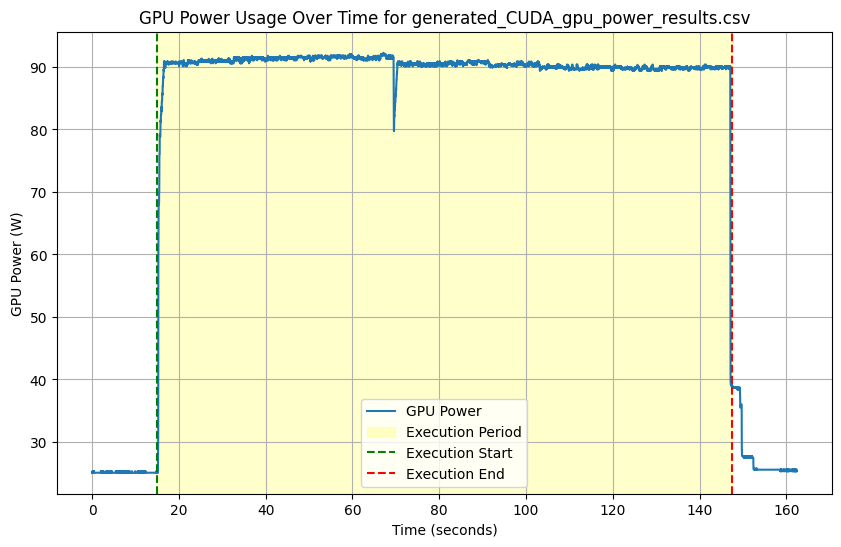

Start time: 15.0 -- End time: 147.378

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 132.38 seconds
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.003319 kWh
  3.3194 Wh
  11949.70 J
Average GPU power: 90.28 W
Total Energy During Exe Runtime:   11949.70 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!
Power and Energy Feedback data: 
  sourcecode_total_energy_joules: 2301.65
  total_energy_joules_refactor: 11949.7
  sourcecode_ave_power: 105.38
  ave_power_refactor: 90.28
  runtime_sourcecode: 21.85
  runtime_refactored: 132.38


***** Generated refactored code is more energy efficient than source code! *****



-----CODE GENERATION COMPLETE-----

CODE GENERATION TIME: 7.1 minutes.

Self-correction count: 1


-----BEGIN CODE COMPARISON-----



----- REVIEW THE CODE COMPARISON PROMPT  (prompt to

The REFACTORED CODE introduces several changes intended to improve energy efficiency by reducing GPU and CPU power consumption. Here are the main differences from the SOURCE CODE that are related to energy efficiency:

1. **Use of Single Precision Arithmetic**:
   - **Change**: The REFACTORED CODE switches from double precision to single precision floating-point arithmetic.
   - **Explanation**: Single precision computations require less computational power and memory bandwidth compared to double precision. This reduction can lead to decreased energy consumption and improved performance on GPUs, which are optimized for single precision operations.

   ```cpp
   // SOURCE CODE
   #define DOUBLE
   #ifdef DOUBLE
   #define Real double
   #define ZERO 0.0
   // ...

   // REFACTORED CODE
   // Use single precision for energy efficiency
   #define Real float
   #define ZERO 0.0f
   // ...
   ```

2. **Increased Block Size**:
   - **Change**: The `BLOCK_SIZE` is increased from 128 to 256.
   - **Explanation**: A larger block size can improve GPU occupancy, allowing more threads to be active simultaneously. Higher occupancy can lead to better utilization of GPU resources, potentially reducing the time each core spends idle and thereby improving energy efficiency.

   ```cpp
   // SOURCE CODE
   #define BLOCK_SIZE 128

   // REFACTORED CODE
   #define BLOCK_SIZE 256
   ```

3. **Optimized Grid and Block Dimensions**:
   - **Change**: The grid and block dimensions are recalculated to ensure that all threads are utilized efficiently.
   - **Explanation**: Adjusting the grid dimension calculations to properly handle cases where the problem size isn't a multiple of the block size ensures that all computational resources are used effectively, reducing wasted computation and improving energy efficiency.

   ```cpp
   // SOURCE CODE
   dim3 block_bcs (BLOCK_SIZE, 1);
   dim3 grid_bcs (NUM / BLOCK_SIZE, 1);

   // REFACTORED CODE
   dim3 block_bcs(BLOCK_SIZE, 1);
   dim3 grid_bcs((NUM + BLOCK_SIZE - 1) / BLOCK_SIZE, 1);
   ```

4. **Use of Thrust Library for Reductions**:
   - **Change**: The REFACTORED CODE utilizes the Thrust library for reductions, such as calculating sums and maximums on the GPU.
   - **Explanation**: Using Thrust's optimized parallel reduction routines allows these operations to be performed directly on the GPU, reducing data transfers between the CPU and GPU. This can lower energy consumption associated with memory transfers and take advantage of the GPU's parallelism for efficiency.

   ```cpp
   // SOURCE CODE
   norm_L2 = ZERO;
   for (int i = 0; i < size_res; ++i) {
     norm_L2 += res[i];
   }

   // REFACTORED CODE
   norm_L2 = thrust::reduce(res, res + size_res, ZERO, thrust::plus<Real>());
   ```

   ```cpp
   // SOURCE CODE
   max_v = SMALL;
   max_u = SMALL;
   for (int i = 0; i < size_max; ++i) {
     max_u = fmax(max_u, max_u_arr[i]);
     max_v = fmax(max_v, max_v_arr[i]);
   }

   // REFACTORED CODE
   max_v = thrust::reduce(max_v_arr, max_v_arr + size_max, SMALL, thrust::maximum<Real>());
   max_u = thrust::reduce(max_u_arr, max_u_arr + size_max, SMALL, thrust::maximum<Real>());
   ```

5. **Simplified Boundary Condition Functions**:
   - **Change**: The boundary condition kernel functions (`set_BCs_host` and `set_BCs`) are simplified by removing unnecessary computations and conditionals.
   - **Explanation**: Simplifying these functions reduces the computational workload, potentially decreasing energy consumption by avoiding redundant operations.

   ```cpp
   // SOURCE CODE
   if (ind == NUM) {
     // Multiple boundary conditions
     // ...
   }

   // REFACTORED CODE
   // Removed unnecessary conditional blocks
   ```

6. **Simplification of Reduction Loops**:
   - **Change**: The shared memory reduction loops in kernels like `sum_pressure`, `calc_residual`, `calculate_u`, and `calculate_v` are rewritten using `for` loops instead of `while` loops.
   - **Explanation**: This change can make the code more readable and may help the compiler optimize the loop unrolling and scheduling, potentially improving performance and energy efficiency.

   ```cpp
   // SOURCE CODE
   int i = BLOCK_SIZE >> 1;
   while (i != 0) {
     if (threadIdx.x < i) {
       sum_cache[threadIdx.x] += sum_cache[threadIdx.x + i];
     }
     __syncthreads();
     i >>= 1;
   }

   // REFACTORED CODE
   for (int i = BLOCK_SIZE / 2; i > 0; i >>= 1) {
     if (threadIdx.x < i) {
       sum_cache[threadIdx.x] += sum_cache[threadIdx.x + i];
     }
     __syncthreads();
   }
   ```

7. **Avoiding Manual Synchronization**:
   - **Change**: Unnecessary `cudaDeviceSynchronize()` calls are removed.
   - **Explanation**: Reducing synchronization points can decrease idle times and overhead, leading to better performance and energy savings.

   ```cpp
   // SOURCE CODE
   // cudaDeviceSynchronize(); // Commented out

   // REFACTORED CODE
   // These synchronization calls are omitted altogether
   ```

8. **Removal of Redundant Calculations**:
   - **Change**: Some redundant calculations and variables are removed or simplified.
   - **Explanation**: Eliminating unnecessary computations reduces the overall number of operations the GPU needs to perform, which can decrease energy consumption.

   ```cpp
   // SOURCE CODE includes redundant boundary condition calculations within if statements

   // REFACTORED CODE simplifies or removes these redundancies
   ```

Overall, these changes in the REFACTORED CODE are intended to improve energy efficiency by:

- Reducing computational precision where high precision is unnecessary (double to float).
- Increasing computational throughput (larger block sizes, optimized loops).
- Making better use of GPU resources (Thrust library for reductions).
- Decreasing data transfer overhead between CPU and GPU (performing reductions on GPU).
- Simplifying code for potential compiler optimizations.

However, it's important to note that while these changes aim to improve energy efficiency, the actual performance and energy consumption can be affected by various factors. In this case, although average power decreased (from 105.38 W to 90.28 W), the total execution time increased significantly (from 21.85 s to 132.38 s), leading to higher total energy consumption.

Metadata file: generated_codes/argo_gpto1preview/promptset_CUDA/metadata_lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp03test_o1p_ee_context_fewsht_compare__02-16-2025_t02_58_48.txt


***** LASSI PIPELINE COMPLETED *****




In [3]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder,
    llm_source, use_context, context_knowledge_selection, code_compiler,
    code_compiler_kwds, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))


# LOAD INPUT CODE TO TRANSLATE
input_code_folder = "HeCBench/" + app_folder_name + "/"
input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()

# SPECIFY OUTPUT CODE SAVE
directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + directory + "/" + file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n\n" + color.BOLD + "***** BEGIN THE LASSI PIPELINE*****" + color.END + "\n\n")

# RUN PIPELINE
complete = lassi.pipeline.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    directory,
    file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure, 
    test_code_first,
    yes_power_feedback
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

### TESTING ONLY

In [4]:
# energy = lassi.getpower.GetGPUpower.idlepower(10)
# print(energy)

# TESTING ONLY
# Names of the CSV files
'''
files = ['translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/generated_OMP_gpu_power_results.csv',
             #'./gpu_power_results_mtdv4.csv',
            ]
# Plot power usage and calculate energy
for file_name in files:
    inference_duration = lassi.getpower.plot_gpu_power(file_name)
    total_energy_joules, ave_power = lassi.getpower.calculate_total_energy(file_name)
    
    # Convert energy units
    total_energy_wh = total_energy_joules / 3600  # Convert from Joules to Watt-hours
    total_energy_kwh = total_energy_wh / 1000  # Convert from Watt-hours to Kilowatt-hours
    
    print(f"Inference duration: {inference_duration:.2f} seconds")
    print(f"Total GPU energy consumption for {file_name}:")
    print(f"  {total_energy_kwh:.6f} kWh")
    print(f"  {total_energy_wh:.4f} Wh")
    print(f"  {total_energy_joules:.2f} J")
    print(f"Average GPU power: {ave_power:.2f} W")
    print("----------------------------------------------------------------------------------------------------------------------------------------")
'''

# TESTING: code execution with power
'''
# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"
exe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"
# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext
input_parameters = [""]
power_measure = True
code_source = "target"
target_lang = "CUDA"

lassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)
'''

'\n# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"\nexe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"\n# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext\ninput_parameters = [""]\npower_measure = True\ncode_source = "target"\ntarget_lang = "CUDA"\n\nlassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)\n'